In [ ]:
import torch

print("--- Checking GPU in PyCharm ---")
if torch.cuda.is_available():
    print(f"Success! PyCharm is using: {torch.cuda.get_device_name(0)}")
else:
    print("PyCharm is still using CPU. Check the interpreter settings.")

In [ ]:
##%% ============================================================
# Cell 1 - Environment Setup (LOCAL - GPU)
# ============================================================

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True,max_split_size_mb:128"

import sys
import gc
import json
import math
import random
import shutil
import subprocess
import importlib.util
from pathlib import Path
from glob import glob
from dataclasses import dataclass, asdict
from collections import Counter
from typing import Optional

def install_if_missing(package_name, import_name=None):
    if import_name is None:
        import_name = package_name
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name, "--quiet"])

install_if_missing("albumentations", "albumentations")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")          # non-interactive backend — works on headless GPU machines
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint as cp
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

try:
    import cv2
    CV2_AVAILABLE = True
except Exception:
    CV2_AVAILABLE = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 80)
print("Cell 1 - Environment Setup (LOCAL - GPU)")
print("=" * 80)
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Albumentations: {A.__version__}")
print(f"Device: {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA: {torch.version.cuda}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    # Enable cuDNN benchmark for faster fixed-size convolutions
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: No GPU detected — training will be slow on CPU.")

gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


Cell 1 - Environment Setup (LOCAL - GPU)
Python: 3.12.8
PyTorch: 2.6.0+cu124
Albumentations: 2.0.8
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA: 12.4
VRAM: 4.29 GB


In [ ]:
##%% ============================================================
# Cell 2 - Configuration and Reproducibility (LOCAL - GPU)
# ============================================================

# ── Change PROJECT_ROOT to wherever your project lives ──────────────────────
# Examples: Linux/Mac: "/home/user/neural_project"   Windows: r"C:\Users\user\Desktop\neural_project"
PROJECT_ROOT = r"C:\Users\rawan\Downloads\neural_project"

DATASET_ZIP        = str(Path(PROJECT_ROOT) / "archive.zip")
EXTRACTED_DIR      = str(Path(PROJECT_ROOT) / "extracted" / "plantsegv2")
DATA_DIR           = str(Path(PROJECT_ROOT) / "data")
OUTPUT_DIR         = str(Path(PROJECT_ROOT) / "outputs")
CHECKPOINT_DIR     = str(Path(PROJECT_ROOT) / "checkpoints")
REPORT_DIR         = str(Path(PROJECT_ROOT) / "outputs" / "report")
INFERENCE_OUTPUT_DIR = str(Path(PROJECT_ROOT) / "outputs" / "external_inference")

@dataclass
class CFG:
    PROJECT_NAME: str  = "Plant Diagnosis with Lesion Segmentation"
    DATASET_NAME: str  = "PlantSeg"

    BASE:  str = DATA_DIR
    IMGS:  str = str(Path(DATA_DIR) / "images")
    MASKS: str = str(Path(DATA_DIR) / "masks")

    OUTPUT_DIR:           str = OUTPUT_DIR
    REPORT_DIR:           str = REPORT_DIR
    INFERENCE_OUTPUT_DIR: str = INFERENCE_OUTPUT_DIR

    SPLITS:     tuple = ("train", "val", "test")
    IMAGE_EXTS: tuple = (".jpg", ".jpeg", ".png")
    MASK_EXTS:  tuple = (".png", ".jpg", ".jpeg")

    SEED:              int  = 42
    DETERMINISTIC:     bool = False
    CUDNN_BENCHMARK:   bool = True   # faster on GPU with fixed input sizes

    IMG_SIZE:          int   = 320
    NUM_CLASSES:       int   = 2
    BATCH_SIZE:        int   = 8
    GRAD_ACCUM:        int   = 2
    NUM_EPOCHS:        int   = 30
    SHOW_EVERY_EPOCHS: int   = 10

    OPTIMIZER_NAME:  str   = "AdamW"
    LR:              float = 5e-4
    SGD_MOMENTUM:    float = 0.9
    WEIGHT_DECAY:    float = 1e-4
    WARMUP_EPOCHS:   int   = 5

    BASE_CH:   int   = 24
    EMA_DECAY: float = 0.999

    # Set NUM_WORKERS > 0 on Linux/Mac for faster data loading.
    # Keep 0 on Windows to avoid multiprocessing issues.
    NUM_WORKERS:        int  = 4 if os.name != "nt" else 2
    PIN_MEMORY:         bool = True
    PERSISTENT_WORKERS: bool = True   # only used when NUM_WORKERS > 0
    DROP_LAST:          bool = True

    AMP:                     bool  = True    # automatic mixed precision (GPU only)
    PATIENCE:                int   = 10
    CLIP_GRAD_NORM:          float = 1.0
    VANISHING_GRAD_THRESHOLD: float = 1e-7
    EXPLODING_GRAD_THRESHOLD: float = 100.0

    MIN_IMAGE_DIM: int = 64

    MIN_LESION_COVERAGE_WARN: float = 0.01
    MAX_LESION_COVERAGE_WARN: float = 80.0

    EXCLUDE_EMPTY_MASKS:          bool = False
    EXCLUDE_MISSING_MASKS:        bool = True
    EXCLUDE_CORRUPT_FILES:        bool = True
    EXCLUDE_OUTLIERS_FROM_TRAINING: bool = False

    IQR_MULTIPLIER:          float = 1.5
    BLUR_THRESHOLD:          float = 20.0
    DARK_IMAGE_THRESHOLD:    float = 25.0
    BRIGHT_IMAGE_THRESHOLD:  float = 235.0
    LOW_CONTRAST_THRESHOLD:  float = 10.0

    DEFAULT_THRESHOLD:     float = 0.5
    THRESHOLD_GRID_START:  float = 0.10
    THRESHOLD_GRID_END:    float = 0.90
    THRESHOLD_GRID_STEP:   float = 0.05

    POST_PROCESS:      bool = True
    POST_MIN_AREA:     int  = 25
    POST_KERNEL_SIZE:  int  = 3

    EXTERNAL_IMAGE_DIR: Optional[str] = None

    BEST_MODEL_PATH:       str = str(Path(CHECKPOINT_DIR) / "best_model.pth")
    LAST_MODEL_PATH:       str = str(Path(CHECKPOINT_DIR) / "last_saved_model.pth")
    FINAL_CHECKPOINT_PATH: str = str(Path(CHECKPOINT_DIR) / "plant_disease_final.pth")
    MODEL_STATE_PATH:      str = str(Path(CHECKPOINT_DIR) / "plant_disease_model_state_dict.pth")
    FULL_MODEL_PATH:       str = str(Path(CHECKPOINT_DIR) / "plant_disease_full_model.pth")

cfg = CFG()

for d in [cfg.OUTPUT_DIR, cfg.REPORT_DIR, cfg.INFERENCE_OUTPUT_DIR, CHECKPOINT_DIR]:
    Path(d).mkdir(parents=True, exist_ok=True)

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if cfg.DETERMINISTIC:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark     = False
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception:
            pass
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark     = cfg.CUDNN_BENCHMARK

def seed_worker(worker_id):
    worker_seed = cfg.SEED + worker_id
    random.seed(worker_seed)
    np.random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(cfg.SEED)
seed_everything(cfg.SEED)

THRESHOLD_GRID = [
    round(float(x), 2)
    for x in np.arange(
        cfg.THRESHOLD_GRID_START,
        cfg.THRESHOLD_GRID_END + 1e-9,
        cfg.THRESHOLD_GRID_STEP
    )
]

with open(os.path.join(cfg.OUTPUT_DIR, "experiment_config.json"), "w") as f:
    json.dump(asdict(cfg), f, indent=4)

print("=" * 80)
print("Cell 2 - Configuration (LOCAL - GPU)")
print("=" * 80)
print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"DEVICE       : {DEVICE}")
print(f"NUM_WORKERS  : {cfg.NUM_WORKERS}")
print(f"AMP          : {cfg.AMP and DEVICE.type == 'cuda'}")
print(f"CUDNN bench  : {cfg.CUDNN_BENCHMARK}")


Cell 2 - Configuration (LOCAL - GPU)
PROJECT_ROOT : C:\Users\rawan\Downloads\neural_project
DEVICE       : cuda
NUM_WORKERS  : 2
AMP          : True
CUDNN bench  : True


In [ ]:
##%% ============================================================
# Cell 3 - Dataset Loading Helpers (LOCAL WINDOWS)
# ============================================================

def find_plantseg_base():
    """Search for dataset in local directories.

    Priority:
    1. data/ directory (images/ + masks/) - complete local copy
    2. extracted/plantsegv2/ (images/ + annotations/) - from archive.zip
    3. Recursive search in PROJECT_ROOT
    """
    candidates = [
        DATA_DIR,
        EXTRACTED_DIR,
    ]

    for p in candidates:
        p = Path(p)
        if (p / "images").exists() and (p / "masks").exists():
            return str(p)
        if (p / "images").exists() and (p / "annotations").exists():
            return str(p)

    root = Path(PROJECT_ROOT)
    if root.exists():
        for p in root.rglob("*"):
            if p.is_dir() and (p / "images").exists() and (
                (p / "annotations").exists() or (p / "masks").exists()
            ):
                return str(p)

    raise FileNotFoundError(
        f"PlantSeg dataset not found.\n"
        f"Expected at: {DATA_DIR} (images/ + masks/)\n"
        f"Or at: {EXTRACTED_DIR} (images/ + annotations/)\n"
        f"Extract archive.zip to: {os.path.join(PROJECT_ROOT, 'extracted')}"
    )

def update_dataset_paths():
    cfg.BASE = find_plantseg_base()
    cfg.IMGS = os.path.join(cfg.BASE, "images")
    if os.path.exists(os.path.join(cfg.BASE, "masks")):
        cfg.MASKS = os.path.join(cfg.BASE, "masks")
    elif os.path.exists(os.path.join(cfg.BASE, "annotations")):
        cfg.MASKS = os.path.join(cfg.BASE, "annotations")
    else:
        cfg.MASKS = os.path.join(cfg.BASE, "masks")

def list_files_with_exts(folder, exts):
    folder = Path(folder)
    files = []
    if not folder.exists():
        return []
    for ext in exts:
        files.extend(folder.glob(f"*{ext}"))
        files.extend(folder.glob(f"*{ext.upper()}"))
    return sorted([str(f) for f in files])

def find_mask_for_image(img_path, mask_dir, mask_exts):
    img_path = Path(img_path)
    mask_dir = Path(mask_dir)
    stem = img_path.stem

    for ext in mask_exts:
        p1 = mask_dir / f"{stem}{ext}"
        p2 = mask_dir / f"{stem}{ext.upper()}"
        if p1.exists():
            return str(p1)
        if p2.exists():
            return str(p2)

    return None

def extract_disease_name_from_filename(img_path):
    return Path(img_path).stem.rsplit("_", 1)[0].replace("_", " ")

update_dataset_paths()

print("=" * 80)
print("Cell 3 - Dataset Loading (LOCAL)")
print("=" * 80)
print(f"BASE : {cfg.BASE}")
print(f"IMGS : {cfg.IMGS}")
print(f"MASKS: {cfg.MASKS}")

for split in cfg.SPLITS:
    img_dir = os.path.join(cfg.IMGS, split)
    mask_dir = os.path.join(cfg.MASKS, split)
    print(
        split,
        len(list_files_with_exts(img_dir, cfg.IMAGE_EXTS)),
        "images |",
        len(list_files_with_exts(mask_dir, cfg.MASK_EXTS)),
        "masks"
    )


Cell 3 - Dataset Loading (LOCAL)
BASE : C:\Users\rawan\Downloads\neural_project\data
IMGS : C:\Users\rawan\Downloads\neural_project\data\images
MASKS: C:\Users\rawan\Downloads\neural_project\data\masks
train 15832 images | 15832 masks
val 2494 images | 2494 masks
test 4590 images | 4590 masks


In [ ]:
##%% ============================================================
# Cell 4 - Dataset Structure Verification
# ============================================================

def verify_split_structure(split, max_samples_to_check=100):
    img_dir = os.path.join(cfg.IMGS, split)
    mask_dir = os.path.join(cfg.MASKS, split)

    image_files = list_files_with_exts(img_dir, cfg.IMAGE_EXTS)
    mask_files = list_files_with_exts(mask_dir, cfg.MASK_EXTS)

    image_stems = {Path(p).stem for p in image_files}
    mask_stems = {Path(p).stem for p in mask_files}

    report = {
        "split": split,
        "num_images": len(image_files),
        "num_masks": len(mask_files),
        "missing_masks": sorted(list(image_stems - mask_stems))[:20],
        "extra_masks": sorted(list(mask_stems - image_stems))[:20],
        "image_sizes": {},
        "mask_sizes": {},
        "non_binary_masks": [],
        "empty_masks": [],
        "errors": [],
    }

    allowed = [{0}, {1}, {255}, {0, 1}, {0, 255}]
    img_counter = Counter()
    mask_counter = Counter()

    for img_path in tqdm(image_files[:max_samples_to_check], desc=f"Verify {split}", leave=False):
        try:
            img = Image.open(img_path).convert("RGB")
            w, h = img.size
            img_counter[(h, w)] += 1

            mask_path = find_mask_for_image(img_path, mask_dir, cfg.MASK_EXTS)
            if mask_path:
                mask = Image.open(mask_path).convert("L")
                mw, mh = mask.size
                mask_counter[(mh, mw)] += 1

                arr = np.array(mask)
                u = set(np.unique(arr).tolist())

                if u not in allowed:
                    report["non_binary_masks"].append(Path(mask_path).name)

                if (arr > 0).sum() == 0:
                    report["empty_masks"].append(Path(mask_path).name)

        except Exception as e:
            report["errors"].append({"file": img_path, "error": str(e)})

    report["image_sizes"] = {str(k): int(v) for k, v in img_counter.items()}
    report["mask_sizes"] = {str(k): int(v) for k, v in mask_counter.items()}
    report["missing_masks_count"] = len(image_stems - mask_stems)
    report["extra_masks_count"] = len(mask_stems - image_stems)
    report["non_binary_masks_count"] = len(report["non_binary_masks"])
    report["empty_masks_count"] = len(report["empty_masks"])

    return report

print("=" * 80)
print("Cell 4 - Dataset Structure Verification")
print("=" * 80)

dataset_report = {"splits": {}}

for split in cfg.SPLITS:
    r = verify_split_structure(split)
    dataset_report["splits"][split] = r
    print(split, r["num_images"], "images |", r["num_masks"], "masks | missing:", r["missing_masks_count"])

with open(os.path.join(cfg.OUTPUT_DIR, "dataset_structure_report.json"), "w") as f:
    json.dump(dataset_report, f, indent=4)

Cell 4 - Dataset Structure Verification


train 15832 images | 15832 masks | missing: 0


val 2494 images | 2494 masks | missing: 0


test 4590 images | 4590 masks | missing: 0


In [ ]:
##%% ============================================================
# Cell 5 - Data Cleaning and Sanity Checks
# ============================================================

def safe_open_image(path, mode="RGB"):
    try:
        return np.array(Image.open(path).convert(mode)), None
    except Exception as e:
        return None, str(e)

def compute_blur_score(image_rgb):
    if not CV2_AVAILABLE:
        return np.nan
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())

def analyze_single_sample(img_path, mask_dir, split):
    rec = {
        "split": split,
        "image_path": img_path,
        "image_name": Path(img_path).name,
        "image_stem": Path(img_path).stem,
        "disease_name": extract_disease_name_from_filename(img_path),
        "mask_path": None,
        "image_ok": False,
        "mask_ok": False,
        "missing_mask": False,
        "corrupt_image": False,
        "corrupt_mask": False,
        "height": np.nan,
        "width": np.nan,
        "channels": np.nan,
        "mask_height": np.nan,
        "mask_width": np.nan,
        "dimension_mismatch": False,
        "too_small_image": False,
        "non_binary_mask": False,
        "empty_mask": False,
        "lesion_pixels": np.nan,
        "total_pixels": np.nan,
        "lesion_coverage_pct": np.nan,
        "brightness_mean": np.nan,
        "contrast_std": np.nan,
        "image_mean": np.nan,
        "image_std": np.nan,
        "black_pixel_ratio": np.nan,
        "white_pixel_ratio": np.nan,
        "blur_score": np.nan,
        "cleaning_flags": "",
        "use_for_training": True,
    }

    flags = []

    image, err = safe_open_image(img_path, "RGB")
    if image is None:
        rec["corrupt_image"] = True
        flags.append("corrupt_image")
        if cfg.EXCLUDE_CORRUPT_FILES:
            rec["use_for_training"] = False
        rec["cleaning_flags"] = "|".join(flags)
        return rec

    rec["image_ok"] = True
    h, w = image.shape[:2]
    c = image.shape[2]
    rec["height"] = int(h)
    rec["width"] = int(w)
    rec["channels"] = int(c)

    if h < cfg.MIN_IMAGE_DIM or w < cfg.MIN_IMAGE_DIM:
        rec["too_small_image"] = True
        flags.append("too_small")
        rec["use_for_training"] = False

    gray = image.mean(axis=2)
    rec["brightness_mean"] = float(gray.mean())
    rec["contrast_std"] = float(gray.std())
    rec["image_mean"] = float(image.mean())
    rec["image_std"] = float(image.std())
    rec["black_pixel_ratio"] = float((gray <= 5).mean())
    rec["white_pixel_ratio"] = float((gray >= 250).mean())
    rec["blur_score"] = compute_blur_score(image)

    mask_path = find_mask_for_image(img_path, mask_dir, cfg.MASK_EXTS)

    if mask_path is None:
        rec["missing_mask"] = True
        flags.append("missing_mask")
        if cfg.EXCLUDE_MISSING_MASKS:
            rec["use_for_training"] = False
        rec["cleaning_flags"] = "|".join(flags)
        return rec

    rec["mask_path"] = mask_path
    mask, err = safe_open_image(mask_path, "L")

    if mask is None:
        rec["corrupt_mask"] = True
        flags.append("corrupt_mask")
        if cfg.EXCLUDE_CORRUPT_FILES:
            rec["use_for_training"] = False
        rec["cleaning_flags"] = "|".join(flags)
        return rec

    rec["mask_ok"] = True
    mh, mw = mask.shape[:2]
    rec["mask_height"] = int(mh)
    rec["mask_width"] = int(mw)

    if (mh, mw) != (h, w):
        rec["dimension_mismatch"] = True
        flags.append("dimension_mismatch")

    allowed = [{0}, {1}, {255}, {0, 1}, {0, 255}]
    u = set(np.unique(mask).tolist())

    if u not in allowed:
        rec["non_binary_mask"] = True
        flags.append("non_binary")

    binary = (mask > 0).astype(np.uint8)
    lesion = int(binary.sum())
    total = int(binary.size)
    coverage = lesion / max(total, 1) * 100

    rec["lesion_pixels"] = lesion
    rec["total_pixels"] = total
    rec["lesion_coverage_pct"] = float(coverage)

    if lesion == 0:
        rec["empty_mask"] = True
        flags.append("empty_mask")
        if cfg.EXCLUDE_EMPTY_MASKS:
            rec["use_for_training"] = False

    rec["cleaning_flags"] = "|".join(flags)

    return rec

def run_cleaning_for_split(split):
    img_dir = os.path.join(cfg.IMGS, split)
    mask_dir = os.path.join(cfg.MASKS, split)
    images = list_files_with_exts(img_dir, cfg.IMAGE_EXTS)

    records = []
    for img_path in tqdm(images, desc=f"Cleaning {split}"):
        records.append(analyze_single_sample(img_path, mask_dir, split))

    df = pd.DataFrame(records)
    path = os.path.join(cfg.OUTPUT_DIR, f"clean_manifest_{split}.csv")
    df.to_csv(path, index=False)
    return df, path

print("=" * 80)
print("Cell 5 - Data Cleaning")
print("=" * 80)

cleaning_results = {}
clean_manifest_paths = {}

for split in cfg.SPLITS:
    df, path = run_cleaning_for_split(split)
    cleaning_results[split] = df
    clean_manifest_paths[split] = path
    print(split, "total:", len(df), "usable:", int(df["use_for_training"].sum()), "manifest:", path)

with open(os.path.join(cfg.OUTPUT_DIR, "data_cleaning_report.json"), "w") as f:
    json.dump({
        s: {
            "total": int(len(df)),
            "usable": int(df["use_for_training"].sum()),
            "missing_masks": int(df["missing_mask"].sum()),
            "corrupt_images": int(df["corrupt_image"].sum()),
            "corrupt_masks": int(df["corrupt_mask"].sum()),
            "empty_masks": int(df["empty_mask"].sum()),
        }
        for s, df in cleaning_results.items()
    }, f, indent=4)

Cell 5 - Data Cleaning


Cleaning train: 100%|██████████| 15832/15832 [15:33<00:00, 16.97it/s] 


train total: 15832 usable: 15830 manifest: C:\Users\rawan\Downloads\neural_project\outputs\clean_manifest_train.csv


Cleaning val: 100%|██████████| 2494/2494 [02:48<00:00, 14.83it/s]


val total: 2494 usable: 2492 manifest: C:\Users\rawan\Downloads\neural_project\outputs\clean_manifest_val.csv


Cleaning test: 100%|██████████| 4590/4590 [05:34<00:00, 13.71it/s]


test total: 4590 usable: 4590 manifest: C:\Users\rawan\Downloads\neural_project\outputs\clean_manifest_test.csv


In [ ]:
##%% ============================================================
# Cell 6 - Outlier Detection
# ============================================================

def iqr_outlier_mask(series, multiplier=1.5):
    s = series.dropna()
    if len(s) < 4:
        return pd.Series(False, index=series.index)

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        return pd.Series(False, index=series.index)

    low = q1 - multiplier * iqr
    high = q3 + multiplier * iqr

    return ((series < low) | (series > high)).fillna(False)

def run_outlier_detection(df):
    df = df.copy()
    df["aspect_ratio"] = df["width"] / df["height"].replace(0, np.nan)

    cols = [
        "height", "width", "aspect_ratio",
        "lesion_coverage_pct",
        "brightness_mean", "contrast_std",
        "image_std", "black_pixel_ratio",
        "white_pixel_ratio", "blur_score"
    ]

    reason_cols = []

    for col in cols:
        if col in df.columns:
            flag = f"outlier_iqr_{col}"
            df[flag] = iqr_outlier_mask(df[col], cfg.IQR_MULTIPLIER)
            reason_cols.append(flag)

    df["outlier_empty_mask"] = df["empty_mask"].fillna(False)
    df["outlier_tiny_lesion"] = (
        (df["lesion_coverage_pct"] > 0) &
        (df["lesion_coverage_pct"] < cfg.MIN_LESION_COVERAGE_WARN)
    ).fillna(False)

    df["outlier_huge_lesion"] = (df["lesion_coverage_pct"] > cfg.MAX_LESION_COVERAGE_WARN).fillna(False)
    df["outlier_dark_image"] = (df["brightness_mean"] < cfg.DARK_IMAGE_THRESHOLD).fillna(False)
    df["outlier_bright_image"] = (df["brightness_mean"] > cfg.BRIGHT_IMAGE_THRESHOLD).fillna(False)
    df["outlier_low_contrast"] = (df["contrast_std"] < cfg.LOW_CONTRAST_THRESHOLD).fillna(False)
    df["outlier_blurry_image"] = (df["blur_score"] < cfg.BLUR_THRESHOLD).fillna(False)

    reason_cols += [
        "outlier_empty_mask",
        "outlier_tiny_lesion",
        "outlier_huge_lesion",
        "outlier_dark_image",
        "outlier_bright_image",
        "outlier_low_contrast",
        "outlier_blurry_image",
    ]

    df["outlier_score"] = df[reason_cols].sum(axis=1).astype(int)
    df["outlier_flag"] = df["outlier_score"] > 0

    def reasons(row):
        out = []
        for col in reason_cols:
            if bool(row[col]):
                out.append(col.replace("outlier_", ""))
        return "|".join(out)

    df["outlier_reasons"] = df.apply(reasons, axis=1)

    if cfg.EXCLUDE_OUTLIERS_FROM_TRAINING:
        df.loc[df["outlier_flag"], "use_for_training"] = False

    return df

print("=" * 80)
print("Cell 6 - Outlier Detection")
print("=" * 80)

outlier_results = {}
manifest_paths = {}

for split in cfg.SPLITS:
    df = run_outlier_detection(cleaning_results[split])
    outlier_results[split] = df
    path = os.path.join(cfg.OUTPUT_DIR, f"clean_manifest_{split}_with_outliers.csv")
    df.to_csv(path, index=False)
    manifest_paths[split] = path
    print(split, "outliers:", int(df["outlier_flag"].sum()), "usable:", int(df["use_for_training"].sum()))

all_outlier_df = pd.concat(outlier_results.values(), ignore_index=True)
all_outlier_df.to_csv(os.path.join(cfg.OUTPUT_DIR, "outlier_detection_full_report.csv"), index=False)

Cell 6 - Outlier Detection
train outliers: 7170 usable: 15830
val outliers: 1124 usable: 2492
test outliers: 1982 usable: 4590


In [ ]:
##%% ============================================================
# Cell 7 - EDA Helpers and Visualizations
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

def get_manifest_path(split):
    p1 = os.path.join(cfg.OUTPUT_DIR, f"clean_manifest_{split}_with_outliers.csv")
    p2 = os.path.join(cfg.OUTPUT_DIR, f"clean_manifest_{split}.csv")

    if os.path.exists(p1):
        return p1
    if os.path.exists(p2):
        return p2

    return None

def load_eda_dataframe():
    dfs = []

    for split in cfg.SPLITS:
        p = get_manifest_path(split)
        if p is not None:
            df = pd.read_csv(p)
            df["split"] = split
            dfs.append(df)

    if not dfs:
        raise FileNotFoundError("Manifest files not found. Ensure previous cells were executed.")

    df = pd.concat(dfs, ignore_index=True)

    if "aspect_ratio" not in df.columns:
        df["aspect_ratio"] = df["width"] / df["height"].replace(0, np.nan)

    return df

def make_overlay(image, mask, color=(255, 0, 0), alpha=0.60):
    overlay = image.copy()
    mask = mask.astype(bool)
    color = np.array(color, dtype=np.float32)
    overlay[mask] = (overlay[mask] * (1 - alpha) + color * alpha).astype(np.uint8)
    return overlay

print("=" * 80)
print("Cell 7 - EDA")
print("=" * 80)

eda_df = load_eda_dataframe()
print(eda_df.groupby("split").size())

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("EDA Summary", fontsize=15, fontweight="bold")

split_counts = eda_df.groupby("split").size().reindex(cfg.SPLITS)
axes[0, 0].bar(split_counts.index, split_counts.values)
axes[0, 0].set_title("Split Counts")

if "disease_name" in eda_df.columns:
    top20 = eda_df[eda_df["split"] == "train"]["disease_name"].value_counts().head(20)
    axes[0, 1].barh(top20.index[::-1], top20.values[::-1])
    axes[0, 1].set_title("Top 20 Disease Categories")
else:
    axes[0, 1].set_title("Disease Categories")

for split in cfg.SPLITS:
    if "lesion_coverage_pct" in eda_df.columns:
        vals = eda_df[eda_df["split"] == split]["lesion_coverage_pct"].dropna()
        if not vals.empty:
            axes[1, 0].hist(vals, bins=40, alpha=0.5, label=split)
axes[1, 0].set_title("Lesion Coverage %")
axes[1, 0].legend()

for split in cfg.SPLITS:
    if "brightness_mean" in eda_df.columns:
        vals = eda_df[eda_df["split"] == split]["brightness_mean"].dropna()
        if not vals.empty:
            axes[1, 1].hist(vals, bins=40, alpha=0.5, label=split)
axes[1, 1].set_title("Brightness")
axes[1, 1].legend()

for ax in axes.ravel():
    ax.grid(alpha=0.3)

plt.tight_layout()

# Save the plot to the output directory
plot_path = os.path.join(cfg.OUTPUT_DIR, "phase7_eda_plots.png")
plt.savefig(plot_path, dpi=120)

# Check backend to prevent FigureCanvasAgg warning
if matplotlib.get_backend().lower() != 'agg':
    plt.show()
else:
    print(f"Plot saved successfully to: {plot_path}")

# Free memory
plt.close(fig)

Cell 7 - EDA
split
test      4590
train    15832
val       2494
dtype: int64
Plot saved successfully to: C:\Users\rawan\Downloads\neural_project\outputs\phase7_eda_plots.png


In [ ]:
##%% ============================================================
# Cell 8 - Enhanced Augmentation Pipeline (for >90% IoU)
# ============================================================
# CHANGELOG:
#   FIX-3a: CoarseDropout -- replaced deprecated parameter names
#           (max_holes, max_height, max_width, min_holes, min_height,
#           min_width, fill_value, mask_fill_value) with the current
#           albumentations >=1.4 API: num_holes_range, hole_height_range,
#           hole_width_range, fill, fill_mask.
#   FIX-3b: ElasticTransform -- removed alpha_affine which is no longer
#           a valid parameter in albumentations >=1.4.

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

def denormalize_tensor(img_t):
    mean = torch.tensor(MEAN).view(3, 1, 1).to(img_t.device)
    std  = torch.tensor(STD).view(3, 1, 1).to(img_t.device)
    return (img_t * std + mean).clamp(0, 1)

def tensor_to_uint8_image(img_t):
    img = denormalize_tensor(img_t.detach().cpu())
    img = img.permute(1, 2, 0).numpy()
    return (img * 255).clip(0, 255).astype(np.uint8)

train_transform = A.Compose([
    A.Resize(cfg.IMG_SIZE, cfg.IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),
    A.Affine(
        scale=(0.80, 1.20),
        rotate=(-30, 30),
        shear=(-10, 10),
        translate_percent=(-0.05, 0.05),
        p=0.50
    ),
    # FIX-3a: Updated to current albumentations >=1.4 parameter names
    A.CoarseDropout(
        num_holes_range=(3, 8),
        hole_height_range=(cfg.IMG_SIZE // 16, cfg.IMG_SIZE // 8),
        hole_width_range=(cfg.IMG_SIZE // 16, cfg.IMG_SIZE // 8),
        fill=0,
        fill_mask=0,
        p=0.5
    ),
    A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3),
    # FIX-3b: Removed alpha_affine (removed from albumentations >=1.4)
    A.ElasticTransform(alpha=1, sigma=50, p=0.3),
    A.ColorJitter(brightness=0.30, contrast=0.30, saturation=0.30, hue=0.10, p=0.50),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 7), p=1.0),
        A.MotionBlur(blur_limit=5, p=1.0),
    ], p=0.30),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(cfg.IMG_SIZE, cfg.IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

test_transform = val_transform
infer_transform = val_transform

print("=" * 80)
print("Cell 8 - Enhanced Augmentation Pipeline [PATCHED]")
print("=" * 80)
print("FIX-3a: CoarseDropout uses current albumentations >=1.4 API")
print("FIX-3b: ElasticTransform deprecated parameter removed")
print("Transforms ready.")


Cell 8 - Enhanced Augmentation Pipeline [PATCHED]
FIX-3a: CoarseDropout uses current albumentations >=1.4 API
FIX-3b: ElasticTransform deprecated parameter removed
Transforms ready.


In [ ]:
##%% ============================================================
# Cell 9 - Dataset Class and DataLoaders
# ============================================================

class PlantSegDataset(Dataset):
    def __init__(
        self,
        split="train",
        transform=None,
        manifest_path=None,
        use_clean_only=True,
        exclude_outliers=False,
        strict_masks=True,
    ):
        self.split = split
        self.transform = transform
        self.manifest_path = manifest_path
        self.use_clean_only = use_clean_only
        self.exclude_outliers = exclude_outliers
        self.strict_masks = strict_masks

        self.img_dir = os.path.join(cfg.IMGS, split)
        self.mask_dir = os.path.join(cfg.MASKS, split)

        self.samples = self._load_samples()

        print(f"{split}: {len(self.samples)} samples")

    def _load_samples(self):
        samples = []

        if self.manifest_path is not None and os.path.exists(self.manifest_path):
            df = pd.read_csv(self.manifest_path)

            if self.use_clean_only and "use_for_training" in df.columns:
                df = df[df["use_for_training"] == True].copy()

            if self.exclude_outliers and "outlier_flag" in df.columns:
                df = df[df["outlier_flag"] == False].copy()

            for _, row in df.iterrows():
                mask_path = row.get("mask_path", None)

                if isinstance(mask_path, float) and np.isnan(mask_path):
                    mask_path = None

                samples.append({
                    "image_path": row["image_path"],
                    "mask_path": mask_path,
                    "image_name": row.get("image_name", Path(row["image_path"]).name),
                    "disease_name": row.get(
                        "disease_name",
                        extract_disease_name_from_filename(row["image_path"])
                    )
                })

        else:
            images = list_files_with_exts(self.img_dir, cfg.IMAGE_EXTS)

            for img_path in images:
                samples.append({
                    "image_path": img_path,
                    "mask_path": find_mask_for_image(img_path, self.mask_dir, cfg.MASK_EXTS),
                    "image_name": Path(img_path).name,
                    "disease_name": extract_disease_name_from_filename(img_path)
                })

        return samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        image = np.array(Image.open(sample["image_path"]).convert("RGB"))
        h, w = image.shape[:2]

        mask_path = sample["mask_path"]

        if mask_path and isinstance(mask_path, str) and os.path.exists(mask_path):
            mask = np.array(Image.open(mask_path).convert("L"))

            if mask.shape[:2] != (h, w):
                mask = np.array(
                    Image.fromarray(mask).resize(
                        (w, h),
                        Image.NEAREST
                    )
                )

            mask = (mask > 0).astype(np.uint8)

        else:
            if self.strict_masks:
                raise FileNotFoundError(f"Mask not found for {sample['image_path']}")
            mask = np.zeros((h, w), dtype=np.uint8)

        if self.transform:
            aug = self.transform(image=image, mask=mask)
            image = aug["image"]
            mask = aug["mask"]

        if not torch.is_tensor(image):
            image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)

        return image, mask.long()

train_manifest = get_manifest_path("train")
val_manifest   = get_manifest_path("val")
test_manifest  = get_manifest_path("test")

print("Train manifest:", train_manifest)
print("Val manifest  :", val_manifest)
print("Test manifest :", test_manifest)

train_ds = PlantSegDataset(
    split="train",
    transform=train_transform,
    manifest_path=train_manifest,
    use_clean_only=True,
    exclude_outliers=cfg.EXCLUDE_OUTLIERS_FROM_TRAINING,
    strict_masks=cfg.EXCLUDE_MISSING_MASKS
)

val_ds = PlantSegDataset(
    split="val",
    transform=val_transform,
    manifest_path=val_manifest,
    use_clean_only=True,
    exclude_outliers=False,
    strict_masks=cfg.EXCLUDE_MISSING_MASKS
)

test_ds = PlantSegDataset(
    split="test",
    transform=test_transform,
    manifest_path=test_manifest,
    use_clean_only=True,
    exclude_outliers=False,
    strict_masks=cfg.EXCLUDE_MISSING_MASKS
)

persistent_workers_flag = cfg.PERSISTENT_WORKERS if cfg.NUM_WORKERS > 0 else False

train_loader = DataLoader(
    train_ds,
    batch_size=cfg.BATCH_SIZE,
    shuffle=True,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
    drop_last=cfg.DROP_LAST,
    persistent_workers=persistent_workers_flag,
    worker_init_fn=seed_worker,
    generator=g
)

val_loader = DataLoader(
    val_ds,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
    drop_last=False,
    persistent_workers=persistent_workers_flag,
    worker_init_fn=seed_worker,
    generator=g
)

test_loader = DataLoader(
    test_ds,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=cfg.PIN_MEMORY,
    drop_last=False,
    persistent_workers=persistent_workers_flag,
    worker_init_fn=seed_worker,
    generator=g
)

print("=" * 80)
print("Cell 9 - DataLoaders")
print("=" * 80)
print(f"Train batches: {len(train_loader)}")
print(f"Val batches  : {len(val_loader)}")
print(f"Test batches : {len(test_loader)}")

Train manifest: C:\Users\rawan\Downloads\neural_project\outputs\clean_manifest_train_with_outliers.csv
Val manifest  : C:\Users\rawan\Downloads\neural_project\outputs\clean_manifest_val_with_outliers.csv
Test manifest : C:\Users\rawan\Downloads\neural_project\outputs\clean_manifest_test_with_outliers.csv
train: 15830 samples
val: 2492 samples
test: 4590 samples
Cell 9 - DataLoaders
Train batches: 1978
Val batches  : 312
Test batches : 574


In [ ]:
##%% ============================================================
# Cell 10 - DataLoader Visualization
# ============================================================

def visualize_dataset_samples(dataset, n=6, save_name="phase10_train_preprocessed_samples.png"):
    n = min(n, len(dataset))
    indices = random.sample(range(len(dataset)), n)

    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for r, idx in enumerate(indices):
        img_t, mask_t = dataset[idx]

        img = tensor_to_uint8_image(img_t)
        mask = mask_t.cpu().numpy().astype(np.uint8)

        overlay = make_overlay(
            img,
            mask,
            color=(255, 50, 50),
            alpha=0.5
        )

        axes[r, 0].imshow(img)
        axes[r, 0].set_title("Image")

        axes[r, 1].imshow(mask, cmap="gray")
        axes[r, 1].set_title(f"Mask values: {np.unique(mask).tolist()}")

        axes[r, 2].imshow(overlay)
        axes[r, 2].set_title("Overlay")

        for ax in axes[r]:
            ax.axis("off")

    plt.tight_layout()

    path = os.path.join(cfg.OUTPUT_DIR, save_name)
    plt.savefig(path, dpi=120)
    plt.show()

    print(f"Saved samples visualization: {path}")

visualize_dataset_samples(
    train_ds,
    n=6,
    save_name="phase10_train_preprocessed_samples.png"
)

images_b, masks_b = next(iter(train_loader))

print("=" * 80)
print("Cell 10 - Batch Test")
print("=" * 80)
print("Batch image:", images_b.shape, images_b.dtype)
print("Batch mask :", masks_b.shape, masks_b.dtype, torch.unique(masks_b))

C:\Users\rawan\AppData\Local\Temp\ipykernel_27964\2148634921.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved samples visualization: C:\Users\rawan\Downloads\neural_project\outputs\phase10_train_preprocessed_samples.png


In [ ]:
##%% ============================================================
# Cell 11 - Model Architecture (Enhanced for >90% IoU)
# ============================================================
# CHANGELOG:
#   FIX-1 (CRITICAL): _init_decoder_weights -- the old guard
#       `if m is not self.encoder` only excluded the single top-level
#       encoder Module object. It did NOT skip Conv2d/BN children inside
#       the encoder, so all ImageNet pretrained weights were silently
#       re-initialized with Kaiming after download.
#       Fix: build encoder_modules = set(self.encoder.modules()) and skip
#       every module that is a member of that set.
#   FIX-4: Replaced brittle ENCODER_CHANNELS hardcoded dict (KeyError for
#       any backbone besides efficientnet_b4) with an auto-detection probe
#       that works with any timm feature extractor.

import timm  # pip install timm

class SEBlock(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        hidden = max(ch // r, 4)
        self.avg = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(ch, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, ch, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.avg(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, 1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, 1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, 1, bias=False),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        psi = self.relu(self.W_g(g) + self.W_x(x))
        psi = self.psi(psi)
        return x * psi


class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.att = AttentionGate(F_g=in_ch // 2, F_l=skip_ch, F_int=max(in_ch // 4, 4))
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch // 2 + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            SEBlock(out_ch)
        )

    def forward(self, x, skip):
        x_up = self.up(x)
        if skip.shape[2:] != x_up.shape[2:]:
            skip = F.interpolate(skip, size=x_up.shape[2:], mode="bilinear", align_corners=False)
        skip_att = self.att(g=x_up, x=skip)
        out = torch.cat([x_up, skip_att], dim=1)
        return self.conv(out)


class EfficientNetAttentionUNet(nn.Module):
    def __init__(self, backbone='efficientnet_b4', out_ch=2, pretrained=True, use_checkpoint=True):
        super().__init__()
        self.use_checkpoint = use_checkpoint

        # Load pretrained encoder
        self.encoder = timm.create_model(
            backbone,
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        # FIX-4: Auto-detect encoder channel widths via dry-run probe.
        # Replaces the old hardcoded ENCODER_CHANNELS dict that raised KeyError
        # for any backbone other than 'efficientnet_b4'.
        with torch.no_grad():
            _probe = torch.zeros(1, 3, 64, 64)
            _feats = self.encoder(_probe)
        enc_chs = [f.shape[1] for f in _feats]
        del _probe, _feats
        print(f"  Encoder channel widths (auto-detected): {enc_chs}")

        # ASPP module on deepest features
        self.aspp = nn.Sequential(
            nn.Conv2d(enc_chs[4], enc_chs[4], 3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(enc_chs[4]),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.3)
        )

        # Decoder
        dec_ch = 256
        self.d4 = DecoderBlock(in_ch=enc_chs[4], skip_ch=enc_chs[3], out_ch=dec_ch)
        self.d3 = DecoderBlock(in_ch=dec_ch,     skip_ch=enc_chs[2], out_ch=128)
        self.d2 = DecoderBlock(in_ch=128,        skip_ch=enc_chs[1], out_ch=64)
        self.d1 = DecoderBlock(in_ch=64,         skip_ch=enc_chs[0], out_ch=32)

        # Final head
        self.out = nn.Sequential(
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, out_ch, 1)
        )

        # Auxiliary heads for deep supervision
        self.aux_d3 = nn.Conv2d(128, out_ch, 1)
        self.aux_d4 = nn.Conv2d(dec_ch, out_ch, 1)

        self._init_decoder_weights()

    def _init_decoder_weights(self):
        # FIX-1 (CRITICAL): Build the full set of encoder sub-modules so every
        # module that is part of the pretrained encoder is skipped.
        # The old code (`if m is not self.encoder`) only skipped the single
        # top-level encoder object, leaving all its child Conv2d and BN layers
        # subject to Kaiming re-initialization -- wiping ImageNet weights.
        encoder_modules = set(self.encoder.modules())
        for m in self.modules():
            if m in encoder_modules:
                continue  # preserve pretrained encoder weights
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if getattr(m, "bias", None) is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _ckpt(self, module, *args):
        if self.use_checkpoint and self.training:
            return cp.checkpoint(module, *args, use_reentrant=False)
        return module(*args)

    def forward(self, x):
        features = self.encoder(x)
        e1, e2, e3, e4, e5 = features

        b  = self._ckpt(self.aspp, e5)
        d4 = self.d4(b,  e4)
        d3 = self.d3(d4, e3)
        d2 = self.d2(d3, e2)
        d1 = self.d1(d2, e1)
        out = self.out(d1)

        # Upsample to input resolution
        out = F.interpolate(out, size=x.shape[2:], mode="bilinear", align_corners=False)

        if self.training:
            aux3 = F.interpolate(self.aux_d3(d3), size=x.shape[2:], mode="bilinear", align_corners=False)
            aux4 = F.interpolate(self.aux_d4(d4), size=x.shape[2:], mode="bilinear", align_corners=False)
            return out, aux3, aux4

        return out


model = EfficientNetAttentionUNet(
    backbone='efficientnet_b4',
    out_ch=cfg.NUM_CLASSES,
    pretrained=True,
    use_checkpoint=True
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 80)
print("Cell 11 - Model Architecture (EfficientNet-B4 Attention U-Net) [PATCHED]")
print("=" * 80)
print(f"Parameters: {n_params:,} ({n_params / 1e6:.2f}M)")
print("FIX-1: Pretrained encoder weights are PRESERVED (_init_decoder_weights fixed).")
print("FIX-4: Encoder channels auto-detected (backbone-agnostic).")


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  Encoder channel widths (auto-detected): [24, 32, 56, 160, 448]
Cell 11 - Model Architecture (EfficientNet-B4 Attention U-Net) [PATCHED]
Parameters: 21,168,502 (21.17M)
FIX-1: Pretrained encoder weights are PRESERVED (_init_decoder_weights fixed).
FIX-4: Encoder channels auto-detected (backbone-agnostic).


In [ ]:
##%% ============================================================
# Cell 12 - Forward Shape Test
# ============================================================
old_checkpoint_state = model.use_checkpoint
model.use_checkpoint = False

model.train()

dummy = torch.randn(
    cfg.BATCH_SIZE,
    3,
    cfg.IMG_SIZE,
    cfg.IMG_SIZE
).to(DEVICE)

with torch.no_grad():
    out = model(dummy)

if isinstance(out, tuple):
    print("Train main:", out[0].shape)
    print("Train aux2:", out[1].shape)
    print("Train aux3:", out[2].shape)
else:
    print("Train:", out.shape)

model.eval()

with torch.no_grad():
    out_eval = model(dummy)

print("Eval:", out_eval.shape)

assert out_eval.shape == (
    cfg.BATCH_SIZE,
    cfg.NUM_CLASSES,
    cfg.IMG_SIZE,
    cfg.IMG_SIZE
)

model.use_checkpoint = old_checkpoint_state

del dummy, out, out_eval

gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

print("Forward shape test passed.")

C:\Users\rawan\gpu_env\Lib\site-packages\torch\nn\modules\conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:217.)
  return F.conv2d(
C:\Users\rawan\gpu_env\Lib\site-packages\torch\nn\modules\linear.py:125: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic be

Train main: torch.Size([8, 2, 320, 320])
Train aux2: torch.Size([8, 2, 320, 320])
Train aux3: torch.Size([8, 2, 320, 320])
Eval: torch.Size([8, 2, 320, 320])
Forward shape test passed.


In [ ]:
##%% ============================================================
# Cell 13 - Enhanced Loss Functions (Tuned for >90% IoU)
# ============================================================

class AdvancedSegmentationLoss(nn.Module):
    """Combined loss with tuned weights for plant disease segmentation.

    From ML Plan: Increase focal α and Tversky β for severe class imbalance.
    """
    def __init__(self):
        super().__init__()

        # Tuned weights (from ML plan recommendation)
        self.ce_w      = 0.15   # reduced (was 0.25)
        self.dice_w    = 0.30   # kept same
        self.focal_w   = 0.30   # increased (was 0.20) — plan says raise α
        self.tversky_w = 0.25   # kept same

        self.ce = nn.CrossEntropyLoss(
            weight=torch.tensor([1.0, 5.0], dtype=torch.float32).to(DEVICE),  # increased lesion weight
            label_smoothing=0.05
        )

    def dice_loss(self, logits, target, smooth=1e-6):
        probs = torch.softmax(logits, dim=1)[:, 1]
        t = target.float()
        inter = (probs * t).sum(dim=(1, 2))
        denom = probs.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
        return 1 - ((2 * inter + smooth) / (denom + smooth)).mean()

    def focal_loss(self, logits, target, gamma=2.5, alpha=0.80):  # increased α from 0.75
        ce = F.cross_entropy(logits, target, reduction="none")
        pt = torch.exp(-ce)
        return (alpha * ((1 - pt) ** gamma) * ce).mean()

    def tversky_loss(self, logits, target, alpha=0.2, beta=0.8, smooth=1e-6):  # increased β for FN penalty
        probs = torch.softmax(logits, dim=1)[:, 1]
        t = target.float()
        tp = (probs * t).sum(dim=(1, 2))
        fp = (probs * (1 - t)).sum(dim=(1, 2))
        fn = ((1 - probs) * t).sum(dim=(1, 2))
        return 1 - ((tp + smooth) / (tp + alpha * fp + beta * fn + smooth)).mean()

    def forward(self, logits, target):
        return (
            self.ce_w      * self.ce(logits, target) +
            self.dice_w    * self.dice_loss(logits, target) +
            self.focal_w   * self.focal_loss(logits, target) +
            self.tversky_w * self.tversky_loss(logits, target)
        )


def deep_supervised_loss(outputs, masks, criterion):
    if isinstance(outputs, tuple):
        main, aux2, aux3 = outputs
        return (
            criterion(main, masks) +
            0.4 * criterion(aux2, masks) +
            0.3 * criterion(aux3, masks)
        )
    return criterion(outputs, masks)

criterion = AdvancedSegmentationLoss().to(DEVICE)

print("=" * 80)
print("Cell 13 - Enhanced Loss Functions")
print("=" * 80)
print("Loss weights: CE=0.15, Dice=0.30, Focal=0.30 (α=0.80), Tversky=0.25 (β=0.80)")
print("Tuned for imbalanced plant lesion segmentation.")

Cell 13 - Enhanced Loss Functions
Loss weights: CE=0.15, Dice=0.30, Focal=0.30 (α=0.80), Tversky=0.25 (β=0.80)
Tuned for imbalanced plant lesion segmentation.


In [ ]:
##%% ============================================================
# Cell 14 - Metrics
# ============================================================

class SegmentationMeter:
    def __init__(self):
        self.reset()

    def reset(self):
        self.tp = 0
        self.fp = 0
        self.fn = 0
        self.tn = 0

    def update(self, preds, targets):
        preds = preds.long()
        targets = targets.long()

        self.tp += ((preds == 1) & (targets == 1)).sum().item()
        self.fp += ((preds == 1) & (targets == 0)).sum().item()
        self.fn += ((preds == 0) & (targets == 1)).sum().item()
        self.tn += ((preds == 0) & (targets == 0)).sum().item()

    def compute(self):
        eps = 1e-6

        precision = self.tp / (self.tp + self.fp + eps)
        recall    = self.tp / (self.tp + self.fn + eps)

        return {
            "iou": self.tp / (self.tp + self.fp + self.fn + eps),
            "dice": (2 * self.tp) / (2 * self.tp + self.fp + self.fn + eps),
            "accuracy": (self.tp + self.tn) / (self.tp + self.tn + self.fp + self.fn + eps),
            "precision": precision,
            "recall": recall,
            "specificity": self.tn / (self.tn + self.fp + eps),
            "f2": (5 * precision * recall) / (4 * precision + recall + eps),
            "tp": self.tp,
            "fp": self.fp,
            "fn": self.fn,
            "tn": self.tn,
        }

def logits_to_probs(logits):
    return torch.softmax(logits, dim=1)[:, 1]

def probs_to_preds(probs, threshold=0.5):
    return (probs >= threshold).long()

def compute_per_sample_metrics(pred_mask, true_mask):
    pred = pred_mask.astype(np.uint8)
    true = true_mask.astype(np.uint8)

    tp = ((pred == 1) & (true == 1)).sum()
    fp = ((pred == 1) & (true == 0)).sum()
    fn = ((pred == 0) & (true == 1)).sum()
    tn = ((pred == 0) & (true == 0)).sum()

    eps = 1e-6

    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)

    return {
        "iou": float(tp / (tp + fp + fn + eps)),
        "dice": float((2 * tp) / (2 * tp + fp + fn + eps)),
        "accuracy": float((tp + tn) / (tp + tn + fp + fn + eps)),
        "precision": float(precision),
        "recall": float(recall),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }

print("=" * 80)
print("Cell 14 - Metrics")
print("=" * 80)
print("Metrics ready.")

Cell 14 - Metrics
Metrics ready.


In [ ]:
##%% ============================================================
# Cell 15 - Optimizer, Scheduler, AMP, and EMA
# ============================================================

if cfg.OPTIMIZER_NAME.lower() == "sgd":
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=cfg.LR,
        momentum=cfg.SGD_MOMENTUM,
        weight_decay=cfg.WEIGHT_DECAY,
        nesterov=True
    )
else:
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg.LR,
        weight_decay=cfg.WEIGHT_DECAY,
        betas=(0.9, 0.999)
    )

def lr_lambda(epoch):
    if epoch < cfg.WARMUP_EPOCHS:
        return float(epoch + 1) / float(max(1, cfg.WARMUP_EPOCHS))

    progress = (epoch - cfg.WARMUP_EPOCHS) / float(
        max(1, cfg.NUM_EPOCHS - cfg.WARMUP_EPOCHS)
    )

    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lr_lambda
)

# FIX-6: Removed dead try/except fallback to torch.cuda.amp.GradScaler.
# torch.amp.GradScaler(device_type, ...) is stable in PyTorch >=2.x.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(cfg.AMP and DEVICE.type == "cuda")
)

class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }
        self.backup = None

    def update(self, model):
        with torch.no_grad():
            for k, v in model.state_dict().items():
                if v.dtype.is_floating_point:
                    self.shadow[k].mul_(self.decay).add_(
                        v.detach(),
                        alpha=1 - self.decay
                    )
                else:
                    self.shadow[k] = v.detach().clone()

    def apply_to(self, model):
        self.backup = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }
        model.load_state_dict(self.shadow, strict=False)

    def restore(self, model):
        if self.backup is not None:
            model.load_state_dict(self.backup, strict=False)
            self.backup = None

ema = EMA(model, cfg.EMA_DECAY)

def get_grad_norm(model):
    total_norm_sq = 0.0
    max_abs_grad = 0.0
    param_count = 0

    for p in model.parameters():
        if p.grad is not None:
            grad = p.grad.detach()
            norm_value = grad.norm(2).item()
            total_norm_sq += norm_value ** 2
            max_abs_grad = max(max_abs_grad, grad.abs().max().item())
            param_count += 1

    total_norm = total_norm_sq ** 0.5

    return total_norm, max_abs_grad, param_count

def diagnose_gradients(grad_norm):
    if grad_norm < cfg.VANISHING_GRAD_THRESHOLD:
        return "VANISHING_GRADIENT_WARNING"

    if grad_norm > cfg.EXPLODING_GRAD_THRESHOLD:
        return "EXPLODING_GRADIENT_WARNING"

    return "OK"

def autocast_context():
    return torch.amp.autocast(
        "cuda",
        enabled=(cfg.AMP and DEVICE.type == "cuda")
    )

print("=" * 80)
print("Cell 15 - Optimizer / Scheduler / AMP / EMA")
print("=" * 80)
print(f"Optimizer: {cfg.OPTIMIZER_NAME}")
print(f"Learning rate: {cfg.LR}")
print(f"AMP: {cfg.AMP and DEVICE.type == 'cuda'}")
print(f"EMA decay: {cfg.EMA_DECAY}")

Cell 15 - Optimizer / Scheduler / AMP / EMA
Optimizer: AdamW
Learning rate: 0.0005
AMP: True
EMA decay: 0.999


Cell 16 - Training Started


Train Epoch 1:   0%|          | 0/1978 [00:00<?, ?it/s]C:\Users\rawan\gpu_env\Lib\site-packages\torch\nn\modules\conv.py:549: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:217.)
  return F.conv2d(
C:\Users\rawan\gpu_env\Lib\site-packages\torch\nn\modules\linear.py:125: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgori

Epoch 001/30 | LR=2.00e-04 | TrainLoss=0.7777 | ValLoss=0.5469 | IoU=0.2477 | Dice=0.3970 | Acc=55.61% | GradNorm=7.6204e-01 | GradStatus=OK | Improved=True


Epoch 002/30 | LR=3.00e-04 | TrainLoss=0.5885 | ValLoss=0.4157 | IoU=0.4954 | Dice=0.6626 | Acc=84.26% | GradNorm=4.9314e-01 | GradStatus=OK | Improved=True


Epoch 003/30 | LR=4.00e-04 | TrainLoss=0.5425 | ValLoss=0.3430 | IoU=0.5981 | Dice=0.7485 | Acc=88.77% | GradNorm=nan | GradStatus=OK | Improved=True


Epoch 004/30 | LR=5.00e-04 | TrainLoss=0.5125 | ValLoss=0.3057 | IoU=0.6326 | Dice=0.7750 | Acc=90.07% | GradNorm=3.9497e-01 | GradStatus=OK | Improved=True


... (2 outputs left out)

Epoch 007/30 | LR=4.92e-04 | TrainLoss=0.4536 | ValLoss=0.2760 | IoU=0.6495 | Dice=0.7875 | Acc=90.39% | GradNorm=3.3674e-01 | GradStatus=OK | Improved=True


Epoch 008/30 | LR=4.82e-04 | TrainLoss=0.4381 | ValLoss=0.2759 | IoU=0.6532 | Dice=0.7902 | Acc=90.52% | GradNorm=3.2225e-01 | GradStatus=OK | Improved=True


Epoch 009/30 | LR=4.69e-04 | TrainLoss=0.4258 | ValLoss=0.2767 | IoU=0.6558 | Dice=0.7921 | Acc=90.67% | GradNorm=3.1135e-01 | GradStatus=OK | Improved=True


Epoch 010/30 | LR=4.52e-04 | TrainLoss=0.4149 | ValLoss=0.2773 | IoU=0.6550 | Dice=0.7915 | Acc=90.64% | GradNorm=3.0749e-01 | GradStatus=OK | Improved=False


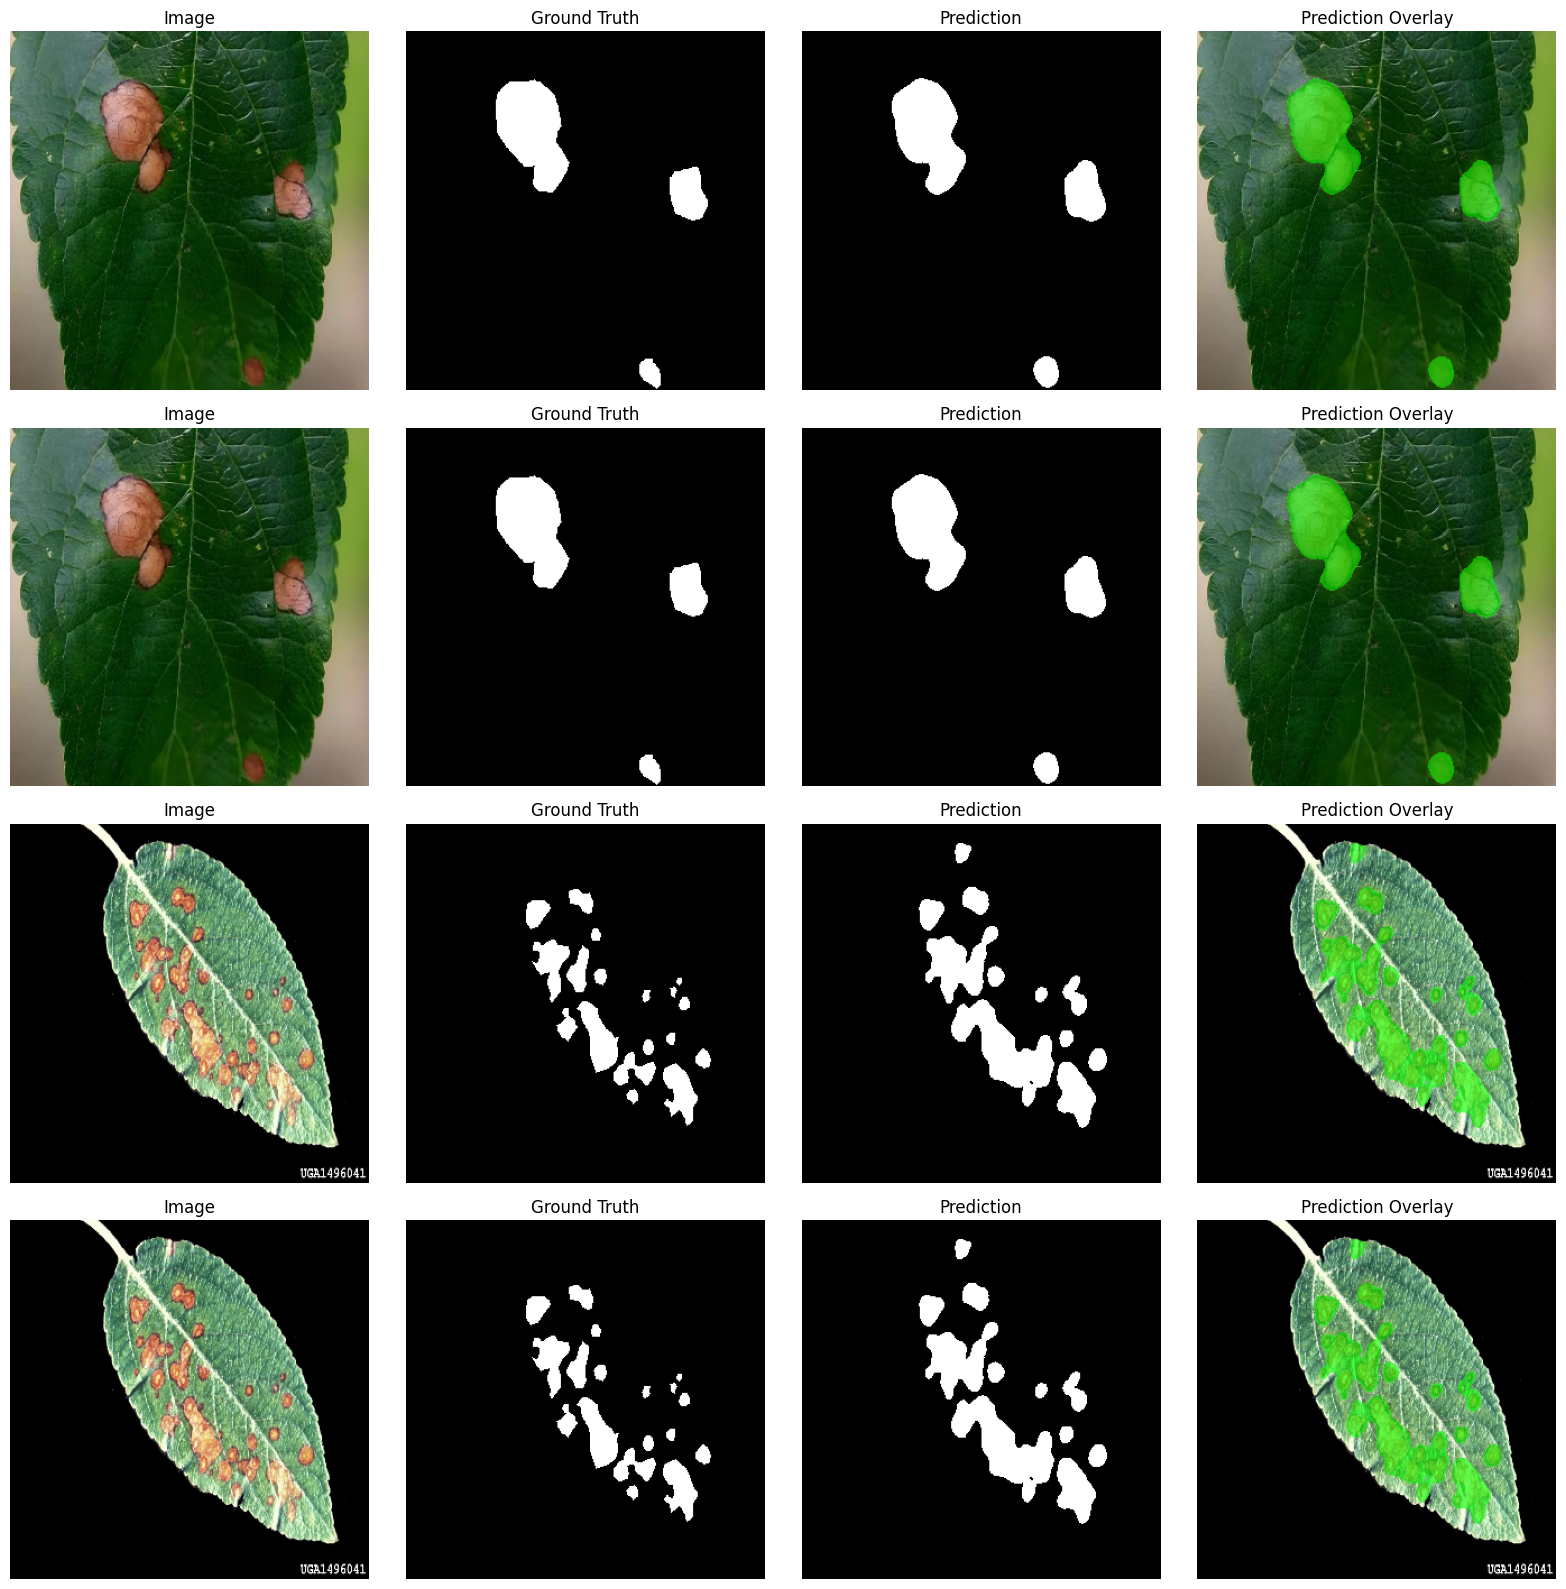

Epoch 011/30 | LR=4.32e-04 | TrainLoss=0.4036 | ValLoss=0.2762 | IoU=0.6606 | Dice=0.7956 | Acc=90.88% | GradNorm=2.9308e-01 | GradStatus=OK | Improved=True


Epoch 012/30 | LR=4.09e-04 | TrainLoss=0.3937 | ValLoss=0.2786 | IoU=0.6613 | Dice=0.7961 | Acc=90.96% | GradNorm=nan | GradStatus=OK | Improved=True


Epoch 013/30 | LR=3.84e-04 | TrainLoss=0.3840 | ValLoss=0.2805 | IoU=0.6612 | Dice=0.7960 | Acc=90.96% | GradNorm=nan | GradStatus=OK | Improved=False


Epoch 014/30 | LR=3.56e-04 | TrainLoss=0.3793 | ValLoss=0.2803 | IoU=0.6613 | Dice=0.7961 | Acc=91.01% | GradNorm=2.8170e-01 | GradStatus=OK | Improved=True


Epoch 015/30 | LR=3.27e-04 | TrainLoss=0.3709 | ValLoss=0.2825 | IoU=0.6612 | Dice=0.7961 | Acc=91.07% | GradNorm=2.6729e-01 | GradStatus=OK | Improved=False


Epoch 016/30 | LR=2.97e-04 | TrainLoss=0.3638 | ValLoss=0.2831 | IoU=0.6604 | Dice=0.7955 | Acc=91.07% | GradNorm=nan | GradStatus=OK | Improved=False


Epoch 017/30 | LR=2.66e-04 | TrainLoss=0.3582 | ValLoss=0.2858 | IoU=0.6591 | Dice=0.7945 | Acc=91.05% | GradNorm=2.5741e-01 | GradStatus=OK | Improved=False


Epoch 018/30 | LR=2.34e-04 | TrainLoss=0.3523 | ValLoss=0.2872 | IoU=0.6598 | Dice=0.7950 | Acc=91.07% | GradNorm=2.4343e-01 | GradStatus=OK | Improved=False


KeyboardInterrupt: 

In [ ]:
##%% ============================================================
# Cell 16 - Training, Validation, and Checkpointing
# ============================================================

class CheckpointManager:
    def __init__(self):
        self.best_iou = -1.0
        self.best_dice = -1.0
        self.best_epoch = -1

    def save(self, path, epoch, model, optimizer, scheduler, scaler, history, metrics):
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "metrics": metrics,
            "config": asdict(cfg),
            "best_iou": self.best_iou,
            "best_dice": self.best_dice,
            "best_epoch": self.best_epoch,
        }, path)

    def save_best_if_needed(self, epoch, model, optimizer, scheduler, scaler, history, metrics):
        improved = metrics["iou"] > self.best_iou

        if improved:
            self.best_iou = metrics["iou"]
            self.best_dice = metrics["dice"]
            self.best_epoch = epoch

            self.save(
                cfg.BEST_MODEL_PATH,
                epoch,
                model,
                optimizer,
                scheduler,
                scaler,
                history,
                metrics
            )

        return improved

    def save_last(self, epoch, model, optimizer, scheduler, scaler, history, metrics):
        self.save(
            cfg.LAST_MODEL_PATH,
            epoch,
            model,
            optimizer,
            scheduler,
            scaler,
            history,
            metrics
        )

checkpoint_manager = CheckpointManager()

history = {
    "epoch": [],
    "lr": [],
    "train_loss": [],
    "val_loss": [],
    "val_iou": [],
    "val_dice": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f2": [],
    "grad_norm": [],
    "max_abs_grad": [],
    "grad_status": [],
}

def train_one_epoch(epoch):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_loss = 0.0
    grad_norm_epoch = 0.0
    max_abs_grad_epoch = 0.0
    grad_status_epoch = "OK"
    grad_steps = 0

    pbar = tqdm(train_loader, desc=f"Train Epoch {epoch}", leave=False)

    for step, (images, masks) in enumerate(pbar):
        images = images.to(DEVICE, non_blocking=True)
        masks  = masks.to(DEVICE, non_blocking=True)

        with autocast_context():
            outputs = model(images)
            loss = deep_supervised_loss(outputs, masks, criterion) / cfg.GRAD_ACCUM

        scaler.scale(loss).backward()

        do_step = (
            ((step + 1) % cfg.GRAD_ACCUM == 0) or
            ((step + 1) == len(train_loader))
        )

        if do_step:
            scaler.unscale_(optimizer)

            grad_norm, max_abs_grad, _ = get_grad_norm(model)
            grad_status = diagnose_gradients(grad_norm)

            grad_norm_epoch += grad_norm
            max_abs_grad_epoch = max(max_abs_grad_epoch, max_abs_grad)
            grad_steps += 1

            if grad_status != "OK":
                grad_status_epoch = grad_status

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                cfg.CLIP_GRAD_NORM
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)
            ema.update(model)

        total_loss += loss.item() * cfg.GRAD_ACCUM

        pbar.set_postfix({
            "loss": f"{total_loss / (step + 1):.4f}",
            "lr": f"{optimizer.param_groups[0]['lr']:.2e}"
        })

        del images, masks, outputs, loss  # FIX-5: inside loop (guards against empty loader)

    avg_loss = total_loss / max(1, len(train_loader))
    avg_grad_norm = grad_norm_epoch / max(1, grad_steps)

    return avg_loss, avg_grad_norm, max_abs_grad_epoch, grad_status_epoch

@torch.no_grad()
def validate_one_epoch(threshold=0.5, use_ema=True):
    if use_ema:
        ema.apply_to(model)

    model.eval()

    total_loss = 0.0
    meter = SegmentationMeter()

    for images, masks in tqdm(val_loader, desc="Validation", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        masks  = masks.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, masks)

        probs = logits_to_probs(logits)
        preds = probs_to_preds(probs, threshold)

        meter.update(preds, masks)

        total_loss += loss.item()

        del images, masks, logits, probs, preds, loss

    metrics = meter.compute()
    metrics["loss"] = total_loss / max(1, len(val_loader))

    if use_ema:
        ema.restore(model)

    return metrics

@torch.no_grad()
def save_epoch_preview(epoch, threshold=0.5):
    model.eval()

    images, masks = next(iter(val_loader))
    images_device = images.to(DEVICE)

    with autocast_context():
        logits = model(images_device)

    probs = logits_to_probs(logits)
    preds = probs_to_preds(probs, threshold).cpu().numpy()

    n = min(images.shape[0], 4)

    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = tensor_to_uint8_image(images[i])
        gt = masks[i].numpy().astype(np.uint8)
        pred = preds[i].astype(np.uint8)
        overlay = make_overlay(img, pred, color=(0, 255, 0))

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Image")

        axes[i, 1].imshow(gt, cmap="gray")
        axes[i, 1].set_title("Ground Truth")

        axes[i, 2].imshow(pred, cmap="gray")
        axes[i, 2].set_title("Prediction")

        axes[i, 3].imshow(overlay)
        axes[i, 3].set_title("Prediction Overlay")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()

    path = os.path.join(cfg.OUTPUT_DIR, f"epoch_{epoch:03d}_preview.png")
    plt.savefig(path, dpi=120)
    plt.show()

print("=" * 80)
print("Cell 16 - Training Started")
print("=" * 80)

patience_counter = 0

for epoch in range(1, cfg.NUM_EPOCHS + 1):
    train_loss, grad_norm, max_abs_grad, grad_status = train_one_epoch(epoch)

    val_metrics = validate_one_epoch(
        cfg.DEFAULT_THRESHOLD,
        use_ema=True
    )

    scheduler.step()
    lr_now = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["lr"].append(lr_now)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["val_iou"].append(val_metrics["iou"])
    history["val_dice"].append(val_metrics["dice"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_precision"].append(val_metrics["precision"])
    history["val_recall"].append(val_metrics["recall"])
    history["val_f2"].append(val_metrics["f2"])
    history["grad_norm"].append(grad_norm)
    history["max_abs_grad"].append(max_abs_grad)
    history["grad_status"].append(grad_status)

    ema.apply_to(model)

    improved = checkpoint_manager.save_best_if_needed(
        epoch,
        model,
        optimizer,
        scheduler,
        scaler,
        history,
        val_metrics
    )

    checkpoint_manager.save_last(
        epoch,
        model,
        optimizer,
        scheduler,
        scaler,
        history,
        val_metrics
    )

    ema.restore(model)

    if improved:
        patience_counter = 0
    else:
        patience_counter += 1

    print(
        f"Epoch {epoch:03d}/{cfg.NUM_EPOCHS} | "
        f"LR={lr_now:.2e} | "
        f"TrainLoss={train_loss:.4f} | "
        f"ValLoss={val_metrics['loss']:.4f} | "
        f"IoU={val_metrics['iou']:.4f} | "
        f"Dice={val_metrics['dice']:.4f} | "
        f"Acc={val_metrics['accuracy'] * 100:.2f}% | "
        f"GradNorm={grad_norm:.4e} | "
        f"GradStatus={grad_status} | "
        f"Improved={improved}"
    )

    if epoch % cfg.SHOW_EVERY_EPOCHS == 0:
        save_epoch_preview(epoch, cfg.DEFAULT_THRESHOLD)

    if patience_counter >= cfg.PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(cfg.OUTPUT_DIR, "training_history.csv"),
    index=False
)

print("=" * 80)
print("Training Completed")
print(f"Best IoU  : {checkpoint_manager.best_iou:.4f}")
print(f"Best Dice : {checkpoint_manager.best_dice:.4f}")
print(f"Best Epoch: {checkpoint_manager.best_epoch}")
print("=" * 80)